# Entrega 2 — Detecção de Duplicatas Semânticas
**Ouvidoria Inteligente: Triagem Semântica de Manifestações Cidadãs**  
**Aluno:** Ricardo Silva Flores

Este notebook calcula uma matriz de similaridade, identifica pares acima de um limiar e discute possíveis falsos positivos e falsos negativos.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

with open('manifestacoes.json', 'r', encoding='utf-8') as arquivo:
    manifestacoes = json.load(arquivo)

df = pd.DataFrame(manifestacoes)
textos = df['texto'].tolist()
modelo = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
embeddings = modelo.encode(textos, show_progress_bar=True)
matriz_similaridade = cosine_similarity(embeddings)
print('Matriz:', matriz_similaridade.shape)

C:\Users\PICHAU\Documents\facul\8periodo\ricardo\OuvidoriaInteligente\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches: 100%|██████████| 2/2 [00:00<00:00,  4.14it/s]

Matriz: (40, 40)


In [2]:
def detectar_duplicatas(textos, limiar=0.85, embeddings_prontos=None):
    """Retorna pares de índices com similaridade de cosseno acima do limiar."""
    if embeddings_prontos is None:
        modelo_local = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
        embeddings_prontos = modelo_local.encode(textos, show_progress_bar=True)
    matriz = cosine_similarity(embeddings_prontos)
    pares = []
    for i in range(len(textos)):
        for j in range(i + 1, len(textos)):
            if matriz[i, j] >= limiar:
                pares.append((i, j, float(matriz[i, j])))
    return pares, matriz

limiar = 0.85
pares_indices, matriz_similaridade = detectar_duplicatas(
    textos, limiar=limiar, embeddings_prontos=embeddings
)

duplicatas = pd.DataFrame([
    {
        'Manifestação A': df.iloc[i]['id'],
        'Manifestação B': df.iloc[j]['id'],
        'Categoria A': df.iloc[i]['categoria_oficial'],
        'Categoria B': df.iloc[j]['categoria_oficial'],
        'Similaridade': round(score, 4),
        'Texto A': df.iloc[i]['texto'],
        'Texto B': df.iloc[j]['texto'],
    }
    for i, j, score in pares_indices
])
duplicatas.sort_values('Similaridade', ascending=False) if not duplicatas.empty else 'Nenhum par acima do limiar.'

'Nenhum par acima do limiar.'

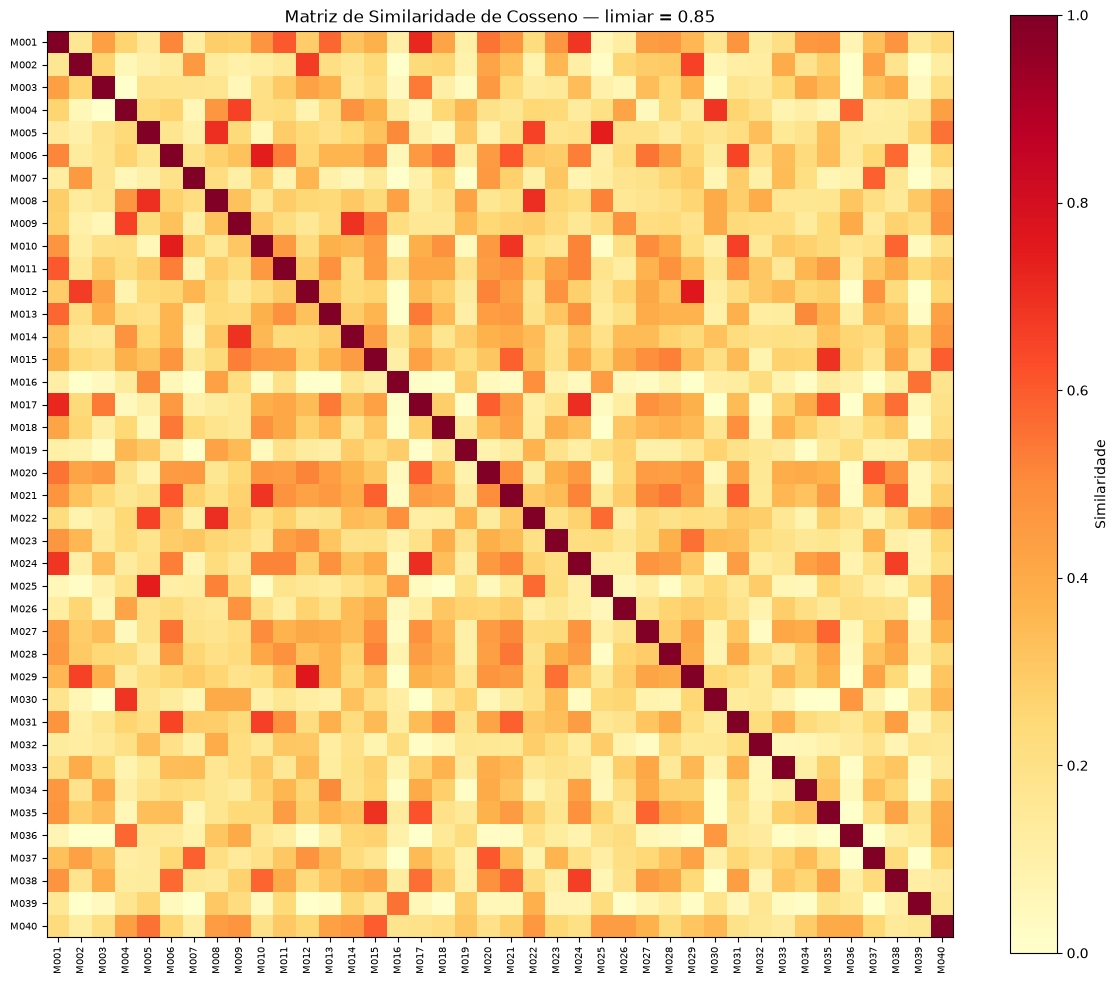

In [3]:
figura, eixo = plt.subplots(figsize=(12, 10))
imagem = eixo.imshow(matriz_similaridade, cmap='YlOrRd', vmin=0, vmax=1)
rotulos = df['id'].tolist()
eixo.set_xticks(range(len(rotulos)))
eixo.set_yticks(range(len(rotulos)))
eixo.set_xticklabels(rotulos, rotation=90, fontsize=7)
eixo.set_yticklabels(rotulos, fontsize=7)
eixo.set_title(f'Matriz de Similaridade de Cosseno — limiar = {limiar}')
figura.colorbar(imagem, ax=eixo, label='Similaridade')
plt.tight_layout()
plt.show()

In [4]:
# Inspeção dos pares mais semelhantes, inclusive abaixo do limiar.
todos_os_pares = []
for i in range(len(df)):
    for j in range(i + 1, len(df)):
        todos_os_pares.append((df.iloc[i]['id'], df.iloc[j]['id'], matriz_similaridade[i, j]))

pd.DataFrame(todos_os_pares, columns=['A', 'B', 'Similaridade']).sort_values('Similaridade', ascending=False).head(20)

,A,B,Similaridade
390,M012,M029,0.759807
188,M006,M010,0.744455
169,M005,M025,0.741823
15,M001,M017,0.717325
510,M017,M024,0.700759
265,M008,M022,0.700534
152,M005,M008,0.696712
474,M015,M035,0.689619
288,M009,M014,0.687900
325,M010,M021,0.687346


## Justificativa do limiar e análise de erros
Foi adotado inicialmente o limiar de 0,85 porque ele privilegia precisão: uma manifestação só é considerada possível duplicata quando possui forte proximidade semântica com outra. Esse valor reduz o risco de agrupar apenas textos da mesma categoria, mas que relatam problemas diferentes.

Como duplicatas esperadas, devem ser inspecionados pares como M003 × M017 (buracos/asfalto esburacado), M008 × M022 (falta de médico ou atendimento no posto) e M010 × M031 (iluminação pública apagada). Dependendo do modelo, um par semanticamente relacionado pode ficar abaixo de 0,85; isso caracteriza possível falso negativo e indica que o limiar deve ser calibrado. Já pares acima do limiar que tratem de subtemas diferentes da mesma categoria devem ser registrados como possíveis falsos positivos.

A interpretação final deve comparar a lista produzida com esses pares esperados, citando os scores obtidos na execução local.